# Lung tissue classification
**Yashwant Bunga and Vinay Ilapuram | BIOL 5340**

We are checking whether 100 expression probe sets can classify tumor and non-tumor tissue nearly as well as 500. We will compare logistic regression and random forest using the same five patient groups. Our cutoff is a drop of no more than five percentage points in balanced accuracy.

Phase 1 prepares the data. The added Phase 2 cells train the models and show our first results. Run the notebook from the top in Colab with a CPU runtime. The last code cell downloads one ZIP with the data and results.


In [1]:

import importlib.util, subprocess, sys
packages = {'numpy': 'numpy', 'pandas': 'pandas', 'sklearn': 'scikit-learn>=1.3',
            'matplotlib': 'matplotlib', 'requests': 'requests'}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Dependencies ready.')


Dependencies ready.


In [2]:
from pathlib import Path
from datetime import datetime, timezone
import csv, gzip, hashlib, io, json, re, shutil, platform
from collections import defaultdict
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from IPython.display import display

SEED = 42
ROOT = Path('/content/Lung_Tissue_Phase1') if Path('/content').exists() else Path.cwd() / 'Lung_Tissue_Phase1'
RAW, OUT, FIG = ROOT / 'raw', ROOT / 'prepared', ROOT / 'figures'
for folder in (RAW, OUT, FIG): folder.mkdir(parents=True, exist_ok=True)
versions = {p: metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'matplotlib', 'requests']}
print('Python:', platform.python_version())
print(json.dumps(versions, indent=2))
print('Output folder:', ROOT)
if not hasattr(__import__('sklearn.model_selection', fromlist=['StratifiedGroupKFold']), 'StratifiedGroupKFold'):
    raise RuntimeError('Upgrade scikit-learn, restart the runtime, then run all cells again.')


Python: 3.13.18
{
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "scikit-learn": "1.6.1",
  "matplotlib": "3.10.0",
  "requests": "2.32.4"
}
Output folder: /content/Lung_Tissue_Phase1


## 1. Getting the data
The data come from [GSE10072 on NCBI GEO](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE10072).


In [3]:
# A retry helps if the NCBI server is temporarily busy.
session = requests.Session()
retry = Retry(total=4, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
session.mount('https://', HTTPAdapter(max_retries=retry))
SOURCES = {
    'GSE10072_series_matrix.txt.gz': 'https://ftp.ncbi.nlm.nih.gov/geo/series/GSE10nnn/GSE10072/matrix/GSE10072_series_matrix.txt.gz',
    'GPL96.annot.gz': 'https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL96/annot/GPL96.annot.gz'
}
def valid_gzip(path):
    try:
        with gzip.open(path, 'rb') as f:
            while f.read(1024 * 1024): pass
        return True
    except (OSError, EOFError):
        return False

def download(url, path):
    if path.exists() and valid_gzip(path):
        print('Using cached:', path.name)
        return
    temp = path.with_suffix(path.suffix + '.part')
    try:
        with session.get(url, stream=True, timeout=(30, 180)) as response:
            response.raise_for_status()
            with temp.open('wb') as f:
                for block in response.iter_content(1024 * 1024):
                    if block: f.write(block)
        if not valid_gzip(temp):
            raise ValueError('The server did not return a valid gzip file.')
        temp.replace(path)
        print('Downloaded:', path.name)
    except Exception as exc:
        temp.unlink(missing_ok=True)
        raise RuntimeError(f'Download failed for {path.name}. Rerun this cell; check NCBI availability if it persists.') from exc

for filename, url in SOURCES.items(): download(url, RAW / filename)
manifest = [{'filename': name, 'url': url,
             'sha256': hashlib.sha256((RAW / name).read_bytes()).hexdigest(),
             'bytes': (RAW / name).stat().st_size} for name, url in SOURCES.items()]
pd.DataFrame(manifest).to_csv(OUT / 'download_manifest.csv', index=False)
display(pd.DataFrame(manifest)[['filename', 'bytes']])


Downloaded: GSE10072_series_matrix.txt.gz
Downloaded: GPL96.annot.gz


,filename,bytes
0,GSE10072_series_matrix.txt.gz,13021909
1,GPL96.annot.gz,4522748


## 2. Matching samples with their labels
Each column in the original table is a tissue sample. The sample titles tell us whether it is tumor or non-tumor and which patient it belongs to. We read those labels directly and keep the sample order matched to the expression values.


In [4]:
with gzip.open(RAW / 'GSE10072_series_matrix.txt.gz', 'rt', encoding='utf-8') as f:
    text = f.read()
lines = text.splitlines()
meta = defaultdict(list)
for line in lines:
    if line.startswith('!Sample_'):
        fields = next(csv.reader([line], delimiter='\t'))
        meta[fields[0]].append(fields[1:])
begin = lines.index('!series_matrix_table_begin')
end = lines.index('!series_matrix_table_end')
expression = pd.read_csv(io.StringIO('\n'.join(lines[begin + 1:end])), sep='\t', index_col=0)
expression.index = expression.index.astype(str)
assert expression.index.is_unique and expression.columns.is_unique, 'Duplicated expression IDs.'
for col in expression.columns: expression[col] = pd.to_numeric(expression[col], errors='raise')
assert not np.isinf(expression.to_numpy()).any(), 'Infinite expression values.'

samples = pd.DataFrame({'sample_id': meta['!Sample_geo_accession'][0],
                        'title': meta['!Sample_title'][0]}).set_index('sample_id')
assert samples.index.is_unique
samples = samples.loc[expression.columns].copy()
for field in ['!Sample_characteristics_ch1', '!Sample_data_processing', '!Sample_platform_id']:
    for j, values in enumerate(meta.get(field, []), 1):
        assert len(values) == len(samples)
        samples[f'{field.removeprefix("!Sample_")}_{j}'] = values

def tissue_label(title):
    if re.search(r'normal\s+lung', title, re.I): return 'Non-tumor'
    if re.search(r'lung\s+tumou?r', title, re.I): return 'Tumor'
    raise ValueError(f'Unrecognized title: {title}')
samples['tissue'] = samples['title'].map(tissue_label)
# We use 0 for non-tumor and 1 for tumor when fitting the models.
samples['target'] = samples['tissue'].map({'Non-tumor': 0, 'Tumor': 1})
samples['patient_id'] = samples['title'].str.extract(r'(GT\d+)', expand=False)
assert samples['patient_id'].notna().all(), 'Unresolved patient codes: inspect titles before proceeding.'
assert len(samples) == 107, f'Expected 107 samples; found {len(samples)}.'
assert samples['tissue'].value_counts().to_dict() == {'Tumor': 58, 'Non-tumor': 49}
assert not samples.duplicated(['patient_id', 'tissue']).any(), 'Repeated patient/tissue combination.'
assert expression.shape[0] >= 500
# Models expect one sample per row, so we turn the original table around.
X = expression.T.copy()
X.index.name = 'sample_id'
y = samples['target'].astype(int)
groups = samples['patient_id']
assert X.index.equals(samples.index)
print(f'Expression matrix: {X.shape[0]} samples × {X.shape[1]} probe sets')
print('Unique patients:', groups.nunique())
display(samples[['title', 'tissue', 'target', 'patient_id']].head(10))
display(samples['tissue'].value_counts().rename('samples').to_frame())


Expression matrix: 107 samples × 22283 probe sets
Unique patients: 74


,title,tissue,target,patient_id
GSM254625,Lung Tumor_GT00006,Tumor,1,GT00006
GSM254626,Normal Lung_GT00006,Non-tumor,0,GT00006
GSM254627,Lung Tumor_GT00007,Tumor,1,GT00007
GSM254628,Normal Lung_GT00007,Non-tumor,0,GT00007
GSM254629,Lung Tumor_GT00022,Tumor,1,GT00022
GSM254630,Lung Tumor_GT00042,Tumor,1,GT00042
GSM254631,Lung Tumor_GT00059,Tumor,1,GT00059
GSM254632,Normal Lung_GT00059,Non-tumor,0,GT00059
GSM254633,Lung Tumor_GT00146,Tumor,1,GT00146
GSM254634,Normal Lung_GT00146,Non-tumor,0,GT00146


,samples
tissue,
Tumor,58
Non-tumor,49


## 3. Checking the expression values
The authors already processed these data using RMA. We check the notes and value range before leaving the values as supplied, so we do not log-transform them twice.

We count missing values and constant probes here, but any filtering used for modeling will be fitted on training samples only. The original study-wide normalization is still a limitation of using processed data.


Submitted processing notes:
Gene expression data were processed and normalized using Bioconductor Affy package, based on the Robust Multichip Average (RMA) method5 for single-channel Affymetrix chips
Quantiles [min, 1%, 25%, median, 75%, 99%, max]: [ 3.67   4.2    6.204  7.426  8.685 12.546 15.248]
Retained submitted RMA expression values; no additional log transformation.


,value
samples,107
probe_sets,22283
patients,74
tumor_samples,58
non_tumor_samples,49
missing_values,0
all_missing_probes_descriptive,0
constant_probes_descriptive,0
identical_expression_rows,0
transformation,Retained submitted RMA expression values; no a...


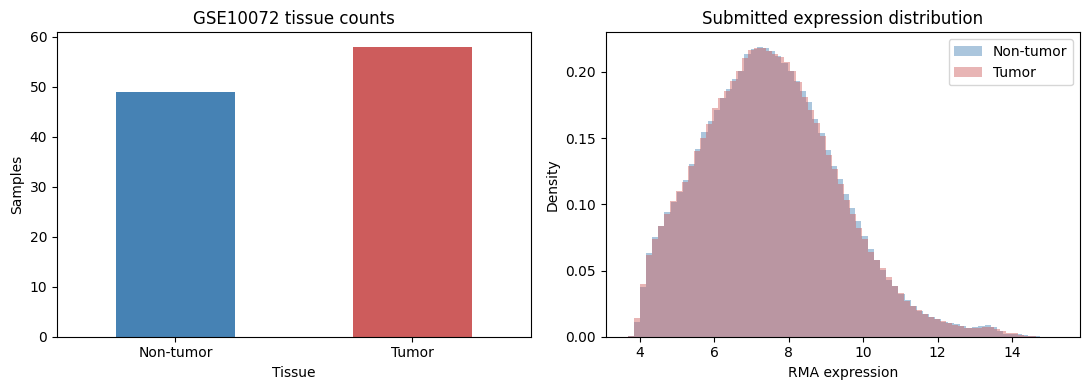

In [5]:
# Check how the original authors processed the data before changing the scale.
processing_notes = sorted(set(v for row in meta.get('!Sample_data_processing', []) for v in row))
(OUT / 'geo_processing_notes.txt').write_text('\n\n'.join(processing_notes), encoding='utf-8')
values = X.to_numpy(dtype=float)
finite = values[np.isfinite(values)]
assert finite.size > 0
q = np.quantile(finite, [0, .01, .25, .5, .75, .99, 1])
print('Submitted processing notes:')
for note in processing_notes: print(note)
print('Quantiles [min, 1%, 25%, median, 75%, 99%, max]:', np.round(q, 3))
rma_documented = any('RMA' in note or 'Robust Multichip Average' in note for note in processing_notes)
assert rma_documented and q[-1] < 40 and q[0] > -20, (
    'Expression scale needs manual review. Do not apply a log transform automatically.')
TRANSFORM = 'Retained submitted RMA expression values; no additional log transformation.'
qc = {
    'samples': len(X), 'probe_sets': X.shape[1], 'patients': int(groups.nunique()),
    'tumor_samples': int((y == 1).sum()), 'non_tumor_samples': int((y == 0).sum()),
    'missing_values': int(X.isna().sum().sum()),
    'all_missing_probes_descriptive': int(X.isna().all().sum()),
    'constant_probes_descriptive': int((X.nunique(dropna=True) <= 1).sum()),
    'identical_expression_rows': int(X.duplicated().sum()),
    'expression_quantiles': q.tolist(), 'transformation': TRANSFORM
}
assert not X.isna().all(axis=1).any(), 'A sample has no expression measurements.'
assert qc['identical_expression_rows'] == 0, 'Identical sample profiles require review.'
(OUT / 'qc_summary.json').write_text(json.dumps(qc, indent=2))
print(TRANSFORM)
display(pd.Series({k:v for k,v in qc.items() if not isinstance(v, list)}, name='value').to_frame())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
samples['tissue'].value_counts().reindex(['Non-tumor', 'Tumor']).plot.bar(ax=ax[0], color=['steelblue', 'indianred'], rot=0)
ax[0].set(title='GSE10072 tissue counts', ylabel='Samples', xlabel='Tissue')
for tissue, color in [('Non-tumor', 'steelblue'), ('Tumor', 'indianred')]:
    v = X.loc[samples['tissue'].eq(tissue)].to_numpy().ravel()
    ax[1].hist(v[np.isfinite(v)], bins=70, density=True, alpha=.45, label=tissue, color=color)
ax[1].set(title='Submitted expression distribution', xlabel='RMA expression', ylabel='Density')
ax[1].legend()
fig.tight_layout()
fig.savefig(FIG / 'phase1_data_checks.png', dpi=180, bbox_inches='tight')
plt.show()


## 4. Matching probes to genes
A probe set is an expression measurement, not always a unique gene. We keep the original probe IDs and add gene symbols where they are available. If a probe has no symbol or several symbols, we flag it instead of guessing.


In [6]:
with gzip.open(RAW / 'GPL96.annot.gz', 'rt', encoding='utf-8') as f:
    annotation_lines = f.read().splitlines()
a_start = annotation_lines.index('!platform_table_begin')
a_end = annotation_lines.index('!platform_table_end')
annotation = pd.read_csv(io.StringIO('\n'.join(annotation_lines[a_start+1:a_end])), sep='\t', dtype=str, keep_default_na=False)
assert 'ID' in annotation.columns, f'Unexpected annotation columns: {annotation.columns.tolist()}'
assert annotation['ID'].is_unique
symbol_candidates = [c for c in annotation.columns if c.strip().lower() in ['gene symbol', 'gene_symbol', 'symbol']]
assert symbol_candidates, f'No gene symbol column found: {annotation.columns.tolist()}'
symbol_col = symbol_candidates[0]
# Join by probe ID so the annotations stay with the right measurements.
probe_map = annotation.set_index('ID').reindex(X.columns)
probe_map.index.name = 'probe_id'
probe_map['gene_symbol'] = probe_map[symbol_col].fillna('')
probe_map['annotation_missing'] = probe_map['gene_symbol'].str.strip().isin(['', '---', 'NA', 'null'])
probe_map['multiple_gene_symbols'] = probe_map['gene_symbol'].str.contains(r'///|;', regex=True)
probe_map.to_csv(OUT / 'probe_annotations.csv.gz', compression='gzip')
print('Probes without gene symbols:', int(probe_map['annotation_missing'].sum()))
print('Probes with multiple gene symbols:', int(probe_map['multiple_gene_symbols'].sum()))
display(probe_map[['gene_symbol', 'annotation_missing', 'multiple_gene_symbols']].head(10))


Probes without gene symbols: 1127
Probes with multiple gene symbols: 1223


,gene_symbol,annotation_missing,multiple_gene_symbols
probe_id,,,
1007_s_at,MIR4640///DDR1,False,True
1053_at,RFC2,False,False
117_at,HSPA6,False,False
121_at,PAX8,False,False
1255_g_at,GUCA1A,False,False
1294_at,MIR5193///UBA7,False,True
1316_at,THRA,False,False
1320_at,PTPN21,False,False
1405_i_at,CCL5,False,False


## 5. Making the validation folds
Some patients have both tumor and non-tumor samples. Those samples need to stay together. Otherwise, the model could see one tissue from a patient during training and another during evaluation.

We split by patient into five folds. Each fold takes a turn as the evaluation set while the other four are used for training. We will reuse these exact splits for every comparison.


In [7]:
# The same patient must never appear on both sides of a split.
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_assignment = pd.Series(-1, index=X.index, name='fold', dtype=int)
split_indices, fold_rows = [], []
for fold, (train_idx, test_idx) in enumerate(splitter.split(X, y, groups), start=1):
    train_patients, test_patients = set(groups.iloc[train_idx]), set(groups.iloc[test_idx])
    assert train_patients.isdisjoint(test_patients), 'Patient leakage.'
    assert y.iloc[train_idx].nunique() == y.iloc[test_idx].nunique() == 2
    assert (fold_assignment.iloc[test_idx] == -1).all()
    fold_assignment.iloc[test_idx] = fold
    split_indices.append((train_idx, test_idx))
    fold_rows.append({'fold': fold, 'train_samples': len(train_idx), 'evaluation_samples': len(test_idx),
                      'train_patients': len(train_patients), 'evaluation_patients': len(test_patients),
                      'evaluation_tumor': int(y.iloc[test_idx].sum()),
                      'evaluation_non_tumor': int((y.iloc[test_idx] == 0).sum()), 'patient_overlap': 0})
assert fold_assignment.ge(1).all()
samples['fold'] = fold_assignment
assert samples.groupby('patient_id')['fold'].nunique().eq(1).all()
fold_summary = pd.DataFrame(fold_rows)
fold_summary.to_csv(OUT / 'fold_summary.csv', index=False)
samples.to_csv(OUT / 'sample_metadata.csv')
np.savez_compressed(OUT / 'cv_indices.npz', **{
    key: arr for i, (tr, te) in enumerate(split_indices, 1)
    for key, arr in [(f'train_{i}', tr), (f'evaluation_{i}', te)]})
display(fold_summary)
print('PASS: every sample has one fold; every patient stays within one fold; both classes occur in all folds.')


,fold,train_samples,evaluation_samples,train_patients,evaluation_patients,evaluation_tumor,evaluation_non_tumor,patient_overlap
0,1,80,27,59,15,13,14,0
1,2,86,21,59,15,10,11,0
2,3,85,22,59,15,11,11,0
3,4,89,18,59,15,11,7,0
4,5,88,19,60,14,13,6,0


PASS: every sample has one fold; every patient stays within one fold; both classes occur in all folds.


## 6. Setting up the model pipelines
The pipeline puts preprocessing and the model together. For each training fold, it handles missing values, removes constant probes, and selects the top 100 or 500 probes using an ANOVA F-test. Logistic regression also gets a scaling step.

Nothing is fitted in this cell. A new pipeline will be fitted inside each fold below, so the evaluation samples do not influence feature selection.


In [8]:
pipeline_source = """from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

def make_pipeline(model_name, k, seed=42):
    if model_name == 'logistic_regression':
        model = LogisticRegression(C=1, solver='lbfgs', max_iter=5000,
                                   class_weight='balanced', random_state=seed)
    elif model_name == 'random_forest':
        model = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                       class_weight='balanced', random_state=seed, n_jobs=-1)
    else:
        raise ValueError('Unknown model: ' + model_name)
    steps = [('impute', SimpleImputer(strategy='median', keep_empty_features=False)),
             ('remove_constant', VarianceThreshold()),
             ('select', SelectKBest(score_func=f_classif, k=k))]
    if model_name == 'logistic_regression':
        steps.append(('scale', StandardScaler()))
    steps.append(('model', model))
    return Pipeline(steps)
"""
(OUT / 'phase2_pipeline.py').write_text(pipeline_source)
namespace = {}
exec(pipeline_source, namespace)
make_pipeline = namespace['make_pipeline']
pipelines = {(name, k): make_pipeline(name, k, SEED)
             for name in ['logistic_regression', 'random_forest'] for k in [100, 500]}
for (name, k), pipe in pipelines.items():
    assert pipe.get_params()['select__k'] == k
    print(name, k, 'features — ready, unfitted')
# Both feature sizes need to be possible in every training fold.
for i, (tr, te) in enumerate(split_indices, 1):
    available = int(X.iloc[tr].nunique(dropna=True).gt(1).sum())
    assert available >= 500, f'Fold {i} has fewer than 500 usable features.'
print('All training folds support both requested feature-set sizes.')


logistic_regression 100 features — ready, unfitted
logistic_regression 500 features — ready, unfitted
random_forest 100 features — ready, unfitted
random_forest 500 features — ready, unfitted
All training folds support both requested feature-set sizes.


## 7. Saving the prepared data
We save the expression table, labels, annotations, and folds before starting the models. These files let us repeat the analysis later. The final cell will package both phases into one ZIP.


In [9]:
X.to_pickle(OUT / 'expression_samples_by_probes.pkl.gz', compression='gzip')
# Only load pickle files produced by this notebook or another trusted source.
X.to_csv(OUT / 'expression_samples_by_probes.csv.gz', compression='gzip')
config = {'dataset': 'GSE10072', 'platform': 'GPL96', 'seed': SEED, 'folds': 5,
          'features': [100, 500], 'models': ['logistic_regression', 'random_forest'],
          'primary_metric': 'balanced_accuracy', 'tolerance': .05,
          'target_encoding': {'Non-tumor': 0, 'Tumor': 1},
          'preprocessing_status': 'unfitted; use training folds only',
          'transformation': TRANSFORM, 'python': platform.python_version(),
          'versions': versions, 'created_utc': datetime.now(timezone.utc).isoformat()}
(OUT / 'project_config.json').write_text(json.dumps(config, indent=2))
(ROOT / 'requirements.txt').write_text('\n'.join(f'{p}=={v}' for p,v in versions.items())+'\n')
(ROOT / 'ai_usage.md').write_text('''# AI use and verification
ChatGPT assisted with notebook code, explanations, and the early Phase 2 comparisons.
The executed notebook records dataset, label, patient-group, scale, and fold checks.
Phase 1 checks data. The added Phase 2 cells fit models using training-only preprocessing.
Add the date, prompt, relevant output, changes, and personal verification for future assistance.
Source conversation: the project planning and notebook-generation conversation in ChatGPT.
''')
(ROOT / 'README.md').write_text('''# Lung Tissue Classification — Phase 1
Authors: Yashwant Bunga and Vinay Ilapuram
Source: https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE10072
Annotation: https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GPL96

## Run
Upload the notebook to Colab, use CPU, and select Runtime > Run all.
Downloads require internet access to NCBI. Save the ZIP before the runtime ends.
The notebook can be rerun; valid cached downloads are reused.

## Contents
raw/: unchanged GEO downloads.
prepared/: unscaled sample-by-probe expression (CSV and trusted pickle), metadata,
probe annotations, QC, fold summary, indices, checksums, config, and pipeline module.
figures/: descriptive QC figure.
requirements.txt: exact versions from this run.
ai_usage.md: assistance and verification record.

## Repeating Phase 2
Load expression_samples_by_probes.csv.gz with index_col=0 and metadata with index_col=0.
Align expression rows to metadata.index. Use target and fold columns from metadata.
For each fold, fit a NEW pipeline on all other folds and predict only the held-out fold.
Never fit imputation, scaling, variance filtering, or supervised selection on all samples.
Use phase2_pipeline.make_pipeline for each model and k in [100, 500].
Compare paired fold balanced accuracies. Patient grouping is already encoded in fold.
The original joint RMA normalization remains a limitation of using processed study data.
Gene mappings are exploratory; one probe is not necessarily one unique gene.

Save the executed notebook separately using Colab File > Download > Download .ipynb.
''')
# Verify exported files align before packaging.
check_x = pd.read_pickle(OUT / 'expression_samples_by_probes.pkl.gz', compression='gzip')
check_meta = pd.read_csv(OUT / 'sample_metadata.csv', index_col=0)
assert check_x.index.equals(check_meta.index)
assert check_x.shape == X.shape
assert check_meta.groupby('patient_id')['fold'].nunique().eq(1).all()
print('Prepared data saved. Next we can fit the models.')


Prepared data saved. Next we can fit the models.


## 8. Starting Phase 2: training the models
 logistic regression and random forest, each with 100 and 500 probe sets. We keep the settings from the proposal rather than changing them after looking at the scores.

We also use a dummy classifier that always predicts the most common training class. It gives us a simple baseline. Balanced accuracy averages how well we recognize each tissue class, so always guessing one class gives 0.5 when both classes are present.


In [10]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
import time

RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
model_names = {'logistic_regression': 'Logistic regression', 'random_forest': 'Random forest'}
runs = [('dummy', None)] + [(name, k) for name in model_names for k in [100, 500]]
score_rows, prediction_rows, selected_rows = [], [], []
start_time = time.perf_counter()

for model_name, k in runs:
    label = 'Dummy baseline' if model_name == 'dummy' else f'{model_names[model_name]} ({k} probes)'
    print(f'Running {label}...', flush=True)
    for fold, (train_idx, test_idx) in enumerate(split_indices, 1):
        # Only these training rows can be used to learn preprocessing or fit the model.
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        assert set(groups.iloc[train_idx]).isdisjoint(groups.iloc[test_idx])
        model = (DummyClassifier(strategy='most_frequent') if model_name == 'dummy'
                 else make_pipeline(model_name, k, SEED))
        # We make a new model for every fold. Nothing carries over from the previous fit.
        model.fit(X_train, y_train)
        predicted = model.predict(X_test)
        fitted_model = model if model_name == 'dummy' else model.named_steps['model']
        tumor_column = list(fitted_model.classes_).index(1)
        tumor_probability = model.predict_proba(X_test)[:, tumor_column]
        score_rows.append({'model': label, 'model_name': model_name, 'features': k, 'fold': fold,
                           'balanced_accuracy': balanced_accuracy_score(y_test, predicted),
                           'f1_tumor': f1_score(y_test, predicted, zero_division=0),
                           'roc_auc': roc_auc_score(y_test, tumor_probability)})
        for sample_id, actual, guess, probability in zip(X_test.index, y_test, predicted, tumor_probability):
            prediction_rows.append({'sample_id': sample_id, 'patient_id': groups.loc[sample_id],
                                    'model': label, 'fold': fold, 'actual': int(actual),
                                    'predicted': int(guess), 'tumor_probability': float(probability)})
        if model_name != 'dummy':
            # Follow the fitted filters to recover the probe IDs selected in this fold.
            kept = np.asarray(X.columns)[~np.isnan(model.named_steps['impute'].statistics_)]
            kept = kept[model.named_steps['remove_constant'].get_support()]
            chosen = kept[model.named_steps['select'].get_support()]
            assert len(chosen) == k
            for probe in chosen:
                selected_rows.append({'model': label, 'fold': fold, 'probe_id': str(probe)})
        # Save after each fold so a later interruption does not erase the finished results.
        pd.DataFrame(score_rows).to_csv(RESULTS / 'fold_scores.csv', index=False)
    print('  Finished all five folds.')

scores = pd.DataFrame(score_rows)
predictions = pd.DataFrame(prediction_rows)
selected_probes = pd.DataFrame(selected_rows)
assert len(scores) == 25  # five configurations, each evaluated on five folds
assert len(predictions) == len(X) * 5
assert not predictions.duplicated(['model', 'sample_id']).any()
assert predictions.groupby('model')['sample_id'].nunique().eq(len(X)).all()
assert predictions.groupby(['model', 'patient_id'])['fold'].nunique().eq(1).all()
predictions.to_csv(RESULTS / 'out_of_fold_predictions.csv', index=False)
selected_probes.to_csv(RESULTS / 'selected_probes_by_fold.csv', index=False)
print(f'Finished in {time.perf_counter() - start_time:.1f} seconds.')


Running Dummy baseline...
  Finished all five folds.
Running Logistic regression (100 probes)...
  Finished all five folds.
Running Logistic regression (500 probes)...
  Finished all five folds.
Running Random forest (100 probes)...
  Finished all five folds.
Running Random forest (500 probes)...
  Finished all five folds.
Finished in 24.4 seconds.


## 9. Comparing the scores
Each number below is the average of the five evaluation-fold scores. The standard deviation shows how much the scores varied between folds; it is not a confidence interval.

The predictions are out of fold: each sample was predicted by a model that did not train on that patient. We have not tested a separate external dataset.


,model,balanced_accuracy_mean,balanced_accuracy_sd,f1_tumor_mean,roc_auc_mean
0,Dummy baseline,0.5000,0.0000,0.7066,0.5
1,Logistic regression (100 probes),0.9838,0.0225,0.9831,1.0
2,Logistic regression (500 probes),0.9838,0.0225,0.9831,1.0
3,Random forest (100 probes),0.9909,0.0203,0.9905,1.0
4,Random forest (500 probes),0.9838,0.0225,0.9831,1.0


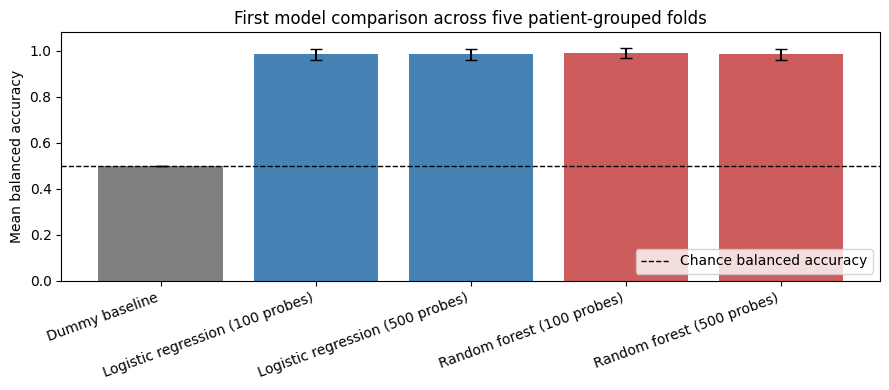

In [11]:
summary = scores.groupby('model', sort=False).agg(
    balanced_accuracy_mean=('balanced_accuracy', 'mean'),
    balanced_accuracy_sd=('balanced_accuracy', 'std'),
    f1_tumor_mean=('f1_tumor', 'mean'),
    roc_auc_mean=('roc_auc', 'mean')
).reset_index()
summary.to_csv(RESULTS / 'model_summary.csv', index=False)
display(summary.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(summary))
ax.bar(x, summary['balanced_accuracy_mean'], color=['gray', 'steelblue', 'steelblue', 'indianred', 'indianred'])
ax.errorbar(x, summary['balanced_accuracy_mean'], yerr=summary['balanced_accuracy_sd'],
            fmt='none', ecolor='black', capsize=4)
ax.axhline(.5, color='black', linestyle='--', linewidth=1, label='Chance balanced accuracy')
ax.set_xticks(x, summary['model'], rotation=20, ha='right')
ax.set(ylim=(0, 1.08), ylabel='Mean balanced accuracy', title='First model comparison across five patient-grouped folds')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIG / 'phase2_model_comparison.png', dpi=180, bbox_inches='tight')
plt.show()


## 10. Where the models made mistakes
The confusion matrices combine the held-out predictions from all five folds. Rows show the actual tissue and columns show the prediction. The diagonal contains correct predictions. These counts use all 107 samples once per model configuration.


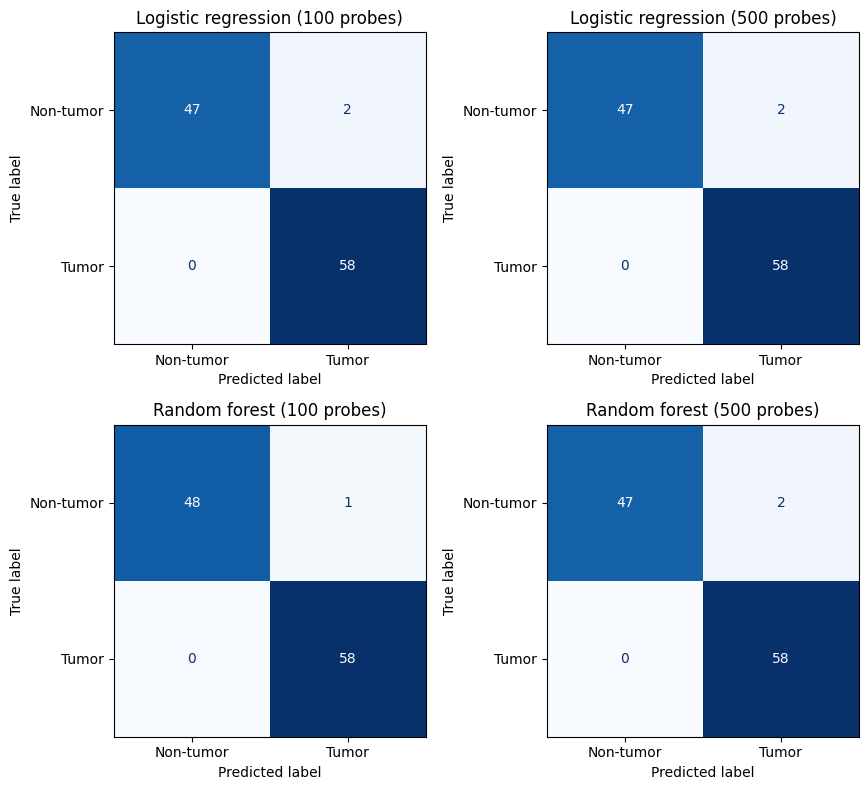

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (name, k) in zip(axes.ravel(), [(name, k) for name in model_names for k in [100, 500]]):
    label = f'{model_names[name]} ({k} probes)'
    part = predictions.loc[predictions['model'].eq(label)]
    cm = confusion_matrix(part['actual'], part['predicted'], labels=[0, 1])
    assert cm.sum() == len(X)
    ConfusionMatrixDisplay(cm, display_labels=['Non-tumor', 'Tumor']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(label)
fig.tight_layout()
fig.savefig(FIG / 'phase2_confusion_matrices.png', dpi=180, bbox_inches='tight')
plt.show()


## 11. Does the smaller feature set meet our cutoff?
For each model, we subtract the 500-probe balanced accuracy from the 100-probe score **within the same fold**. A mean difference of -0.05 means the smaller set lost five percentage points. A positive difference means it did better.

We see whether each model meets our chosen cutoff, but this is a small, within-study comparison. Passing the cutoff does not prove statistical equivalence or clinical usefulness. The folds overlap in their training data, so we do not treat them as five independent experiments.


In [13]:
comparison_rows = []
for name, nice_name in model_names.items():
    part = scores.loc[scores['model_name'].eq(name)]
    paired = part.pivot(index='fold', columns='features', values='balanced_accuracy').sort_index()
    assert paired.shape == (5, 2) and paired.notna().all().all()
    difference = paired[100] - paired[500]
    for fold, value in difference.items():
        print(f'{nice_name}, fold {fold}: {value * 100:+.2f} percentage points')
    mean_difference = float(difference.mean())
    comparison_rows.append({'model': nice_name,
                            'mean_difference_percentage_points': 100 * mean_difference,
                            'sd_difference_percentage_points': 100 * float(difference.std(ddof=1)),
                            'meets_5_point_cutoff': bool(mean_difference >= -.05 - 1e-12)})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RESULTS / 'feature_set_comparison.csv', index=False)
display(comparison.round(3))

# Build this short interpretation from the scores produced by this run.
notes = []
for row in comparison.itertuples(index=False):
    outcome = 'met' if row.meets_5_point_cutoff else 'did not meet'
    notes.append(f'{row.model}: the 100-probe set {outcome} the five-point cutoff. '
                 f'The mean change was {row.mean_difference_percentage_points:+.2f} percentage points.')
answer = 'Both models met the cutoff in this run.' if comparison['meets_5_point_cutoff'].all() else 'The overall cutoff was not met by both models in this run.'
notes.extend([answer,
              'These are preliminary results on GSE10072, not an external validation.',
              'We still need to interpret selected probes and finish the report and presentation.'])
interpretation = '\n'.join(notes)
print(interpretation)
(RESULTS / 'preliminary_interpretation.txt').write_text(interpretation, encoding='utf-8')


Logistic regression, fold 1: +0.00 percentage points
Logistic regression, fold 2: +0.00 percentage points
Logistic regression, fold 3: +0.00 percentage points
Logistic regression, fold 4: +0.00 percentage points
Logistic regression, fold 5: +0.00 percentage points
Random forest, fold 1: +3.57 percentage points
Random forest, fold 2: +0.00 percentage points
Random forest, fold 3: +0.00 percentage points
Random forest, fold 4: +0.00 percentage points
Random forest, fold 5: +0.00 percentage points


,model,mean_difference_percentage_points,sd_difference_percentage_points,meets_5_point_cutoff
0,Logistic regression,0.000,0.000,True
1,Random forest,0.714,1.597,True


Logistic regression: the 100-probe set met the five-point cutoff. The mean change was +0.00 percentage points.
Random forest: the 100-probe set met the five-point cutoff. The mean change was +0.71 percentage points.
Both models met the cutoff in this run.
These are preliminary results on GSE10072, not an external validation.
We still need to interpret selected probes and finish the report and presentation.


409

## 12. Saving the results


In [14]:
config['analysis_status'] = 'Phase 1 and initial Phase 2 comparisons completed'
config['preprocessing_status'] = 'Fitted separately on training data within each fold'
config['model_summary'] = summary.to_dict(orient='records')
config['feature_set_comparison'] = comparison.to_dict(orient='records')
(OUT / 'project_config.json').write_text(json.dumps(config, indent=2))
readme = (ROOT / 'README.md').read_text()
readme += '\n## Initial Phase 2 results\nThe same notebook now runs all four model configurations and a dummy baseline.\nresults/ contains fold_scores.csv, model_summary.csv, out_of_fold_predictions.csv,\nselected_probes_by_fold.csv, feature_set_comparison.csv, and preliminary_interpretation.txt.\nfigures/ also contains the comparison plot and confusion matrices.\nAll preprocessing was fitted inside training folds. These are within-study results;\nbiological interpretation and independent validation have not been completed.\n'
(ROOT / 'README.md').write_text(readme)
ai_notes = (ROOT / 'ai_usage.md').read_text()
ai_notes += '\n## Initial Phase 2 addition\nRequest: extend the uploaded notebook with early model results and clearer student-style explanations.\nChatGPT assisted with model-loop code, metrics, plots, and wording.\nChecks in code verify identical folds, patient separation, one prediction per sample\nper configuration, selected feature counts, and saved output alignment.\nScores and conclusions are calculated from this run rather than typed in manually.\nKeep the executed notebook and review the outputs before using them in the report.\n'
(ROOT / 'ai_usage.md').write_text(ai_notes)
archive = shutil.make_archive(str(ROOT.parent / 'Lung_Tissue_Phase1_and_Phase2_outputs'), 'zip', root_dir=ROOT)
print('Prepared data and first model results saved.')
print('ZIP:', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Outside Colab: use the ZIP at the path above.')


Prepared data and first model results saved.
ZIP: /content/Lung_Tissue_Phase1_and_Phase2_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Sources
- [GSE10072 dataset](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE10072)
- [Submitted processing notes](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSM254625)
- [GPL96 annotation](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GPL96)
- [StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

These are our first model comparisons on one dataset.
